# AI for Business Analytics — Mini Project
## Smart Airbnb Pricing System
**Goal:** predict the nightly price of an Airbnb listing 

**Dataset:** Kaggle *Airbnb Price Prediction* (`train.csv`) 

**Main model:** Linear Regression 

### Project workflow
1. Import libraries and load the data
2. Understand the data and check its quality
3. Clean the data
4. Feature engineering (turn raw columns, especially `amenities`, into model-ready features)
5. Exploratory Data Analysis (EDA) and business insights
6. Select features, split into train / test
7. Build and train the models
8. Evaluate (MAE, RMSE, R²) and plot actual vs predicted
9. Explain the Linear Regression (what increases the price?)
10. Predict a price for a new listing, then save the model for a website

In [1]:
from pathlib import Path

DATASET_PATH = Path("train.csv")
if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        "train.csv was not found. Place the original Kaggle dataset in this project directory; "
        "the notebook will not generate or replace it."
    )
print(f"Using the original dataset at {DATASET_PATH.resolve()}")


Using the original dataset at /Users/anishmd/Desktop/Project_DSA1.0/College_Notes/PE_miniproject/AI-MP/train.csv


In [2]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 100

In [3]:
from src.train import load_dataset

df = load_dataset(DATASET_PATH)


## 3. Understand the dataset

* Each **row = one Airbnb listing**.
* The target column is **`log_price`** = the *natural logarithm* of the nightly price in US dollars.
  So the real price is `price = e^(log_price)`  (in code: `np.exp(log_price)`).
* Prices are *right-skewed* (a few very expensive listings), so the dataset authors stored the log.
  Models usually predict the log price better, and we convert back to dollars at the end.

In [4]:
print("Shape (rows, columns):", df.shape)

print("\nColumn types:")
display(df.dtypes.to_frame("type"))

print("\nMissing values (only columns that have some):")
missing = df.isna().sum()
display(missing[missing > 0].sort_values(ascending=False).to_frame("missing values"))

print("\nNumeric summary:")
display(df[["log_price", "accommodates", "bathrooms", "bedrooms", "beds"]].describe().round(2))

print("\nListings per city:")
display(df["city"].value_counts().to_frame("listings"))

print("\nListings per room type:")
display(df["room_type"].value_counts().to_frame("listings"))

Shape (rows, columns): (74111, 29)

Column types:


,type
id,int64
log_price,float64
property_type,object
room_type,object
amenities,object
accommodates,int64
bathrooms,float64
bed_type,object
cancellation_policy,object
cleaning_fee,bool



Missing values (only columns that have some):


,missing values
host_response_rate,18299
review_scores_rating,16722
first_review,15864
last_review,15827
thumbnail_url,8216
neighbourhood,6872
zipcode,966
bathrooms,200
host_has_profile_pic,188
host_identity_verified,188



Numeric summary:


,log_price,accommodates,bathrooms,bedrooms,beds
count,74111.00,74111.00,73911.00,74020.00,73980.00
mean,4.78,3.16,1.24,1.27,1.71
std,0.72,2.15,0.58,0.85,1.25
min,0.00,1.00,0.00,0.00,0.00
25%,4.32,2.00,1.00,1.00,1.00
50%,4.71,2.00,1.00,1.00,1.00
75%,5.22,4.00,1.00,1.00,2.00
max,7.60,16.00,8.00,10.00,18.00



Listings per city:


,listings
city,
NYC,32349
LA,22453
SF,6434
DC,5688
Chicago,3719
Boston,3468



Listings per room type:


,listings
room_type,
Entire home/apt,41310
Private room,30638
Shared room,2163


## 4. Data quality checks and cleaning

Checks and decisions:

1. **Duplicates:** remove exact duplicate rows (and duplicate listing `id`s).
2. **Invalid target:** `log_price = 0` means a price of $1 per night — not a real price, so those rows are removed.
3. **Create the real `price` column** in dollars from `log_price`.
4. **Expensive listings are kept.** Luxury homes are real; we do not delete them with an arbitrary cap.
   The log transformation already reduces their influence.
5. **Missing predictor values** (e.g. missing `bathrooms`) are filled *inside the model pipeline*,
   using only the training data. This avoids "data leakage" from the test set.

In [5]:
# Keep one row per listing and retain every finite, non-negative log price.
target_values = pd.to_numeric(df["log_price"], errors="coerce")
valid_target = target_values.notna() & np.isfinite(target_values) & (target_values >= 0)
df_clean = df.loc[valid_target].drop_duplicates(subset=["id"], keep="first").copy()
df_clean["log_price"] = target_values.loc[df_clean.index]
df_clean["price"] = np.exp(df_clean["log_price"])

print(f"Total cleaned listings: {len(df_clean):,}")
print(f"Price range: ${df_clean['price'].min():,.0f} to ${df_clean['price'].max():,.0f} per night")


Total cleaned listings: 74,111
Price range: $1 to $1,999 per night


## 5. Feature engineering

Raw columns are not always ready for a model. Here we prepare them:

* **`amenities`** is one long text like `{"Wireless Internet","Kitchen",Heating,...}`.
  We turn the most important amenities into simple **0/1 columns** (1 = the listing has it).
* **`cleaning_fee`** (True/False) and **`instant_bookable`** (t/f) become 1/0.
* **`neighbourhood`** has missing values → we label them `"Unknown"`.

We do **not** use `id`, `name`, `description`, `thumbnail_url` or review columns:
they are identifiers/free text, and a *brand-new* listing has no reviews yet,
so a new-listing price estimator should not depend on them.

In [6]:
from src.predict_price import (
    AMENITY_FEATURES,
    CATEGORICAL_FEATURES,
    FEATURE_COLUMNS,
    NUMERIC_FEATURES,
)
from src.train import prepare_features

# The shared extractor keeps notebook columns identical to training and prediction.
X = prepare_features(df_clean)
ALL_FEATURES = list(FEATURE_COLUMNS)


## 6. Exploratory Data Analysis (EDA)

EDA = looking at the data with charts before modelling. These charts can go straight into your report.
We use the **median** as well as the mean because a few luxury listings pull the mean upwards.

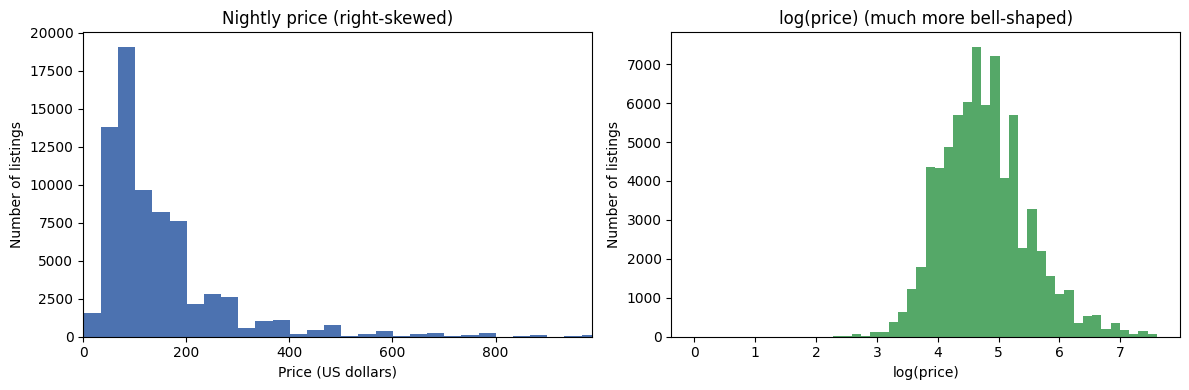

,median,mean,count
city,,,
Chicago,99.0,132.5,3719
LA,100.0,155.4,22453
NYC,105.0,143.0,32349
DC,125.0,217.9,5688
Boston,136.0,165.6,3468
SF,165.0,227.4,6434


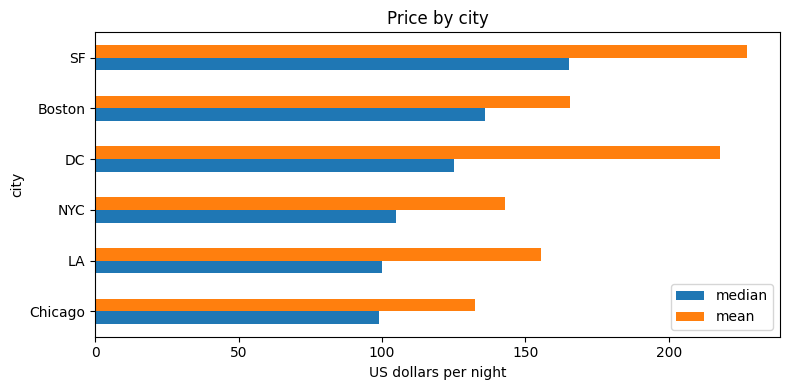

,median,mean,count
room_type,,,
Shared room,45.0,63.7,2163
Private room,75.0,88.5,30638
Entire home/apt,160.0,218.7,41310


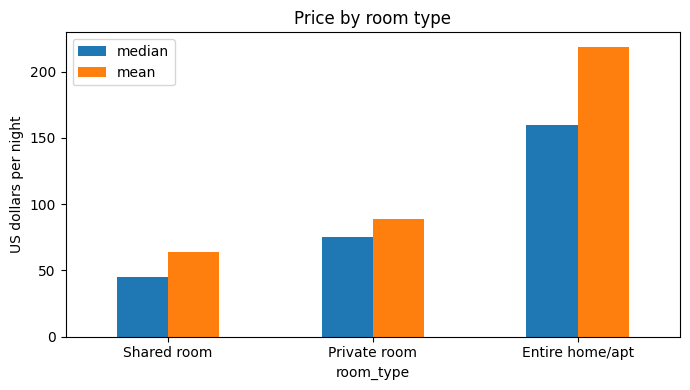

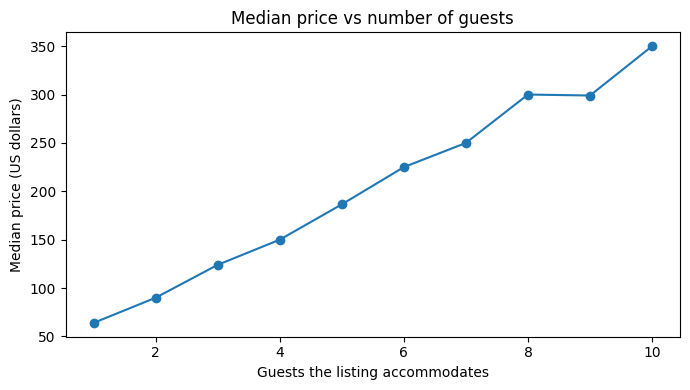

In [7]:
# ---- Chart 1: price distribution, normal vs log scale ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_clean["price"], bins=60, color="#4C72B0")
axes[0].set_xlim(0, df_clean["price"].quantile(0.99))   # zoom in for readability only
axes[0].set_title("Nightly price (right-skewed)")
axes[0].set_xlabel("Price (US dollars)"); axes[0].set_ylabel("Number of listings")

axes[1].hist(df_clean["log_price"], bins=50, color="#55A868")
axes[1].set_title("log(price) (much more bell-shaped)")
axes[1].set_xlabel("log(price)"); axes[1].set_ylabel("Number of listings")
plt.tight_layout(); plt.show()

# ---- Chart 2: price by city ----
city_summary = df_clean.groupby("city")["price"].agg(["median", "mean", "count"]).sort_values("median")
display(city_summary.round(1))
city_summary[["median", "mean"]].plot(kind="barh", figsize=(8, 4), title="Price by city")
plt.xlabel("US dollars per night"); plt.tight_layout(); plt.show()

# ---- Chart 3: price by room type ----
room_summary = df_clean.groupby("room_type")["price"].agg(["median", "mean", "count"]).sort_values("median")
display(room_summary.round(1))
room_summary[["median", "mean"]].plot(kind="bar", figsize=(7, 4), title="Price by room type")
plt.ylabel("US dollars per night"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# ---- Chart 4: price vs number of guests ----
guest_summary = df_clean.groupby("accommodates")["price"].median()
guest_summary = guest_summary[guest_summary.index <= 10]
guest_summary.plot(kind="line", marker="o", figsize=(7, 4), title="Median price vs number of guests")
plt.xlabel("Guests the listing accommodates"); plt.ylabel("Median price (US dollars)")
plt.tight_layout(); plt.show()

## 7. Business analytics findings

The numbers below are computed from the data, so you can quote them in your report.
They show **differences and relationships** — they do not prove that one factor *causes* a price change.

In [8]:
top_city, low_city = city_summary["median"].idxmax(), city_summary["median"].idxmin()
top_room, low_room = room_summary["median"].idxmax(), room_summary["median"].idxmin()

print(f"Most expensive city (median) : {top_city}  (${city_summary.loc[top_city, 'median']:.0f}/night)")
print(f"Cheapest city (median)       : {low_city}  (${city_summary.loc[low_city, 'median']:.0f}/night)")
print(f"Most expensive room type     : {top_room}  (${room_summary.loc[top_room, 'median']:.0f}/night)")
print(f"Cheapest room type           : {low_room}  (${room_summary.loc[low_room, 'median']:.0f}/night)")

rows = []
for col in AMENITY_FEATURES:
    with_it = df_clean.loc[X[col] == 1, "price"].median()
    without = df_clean.loc[X[col] == 0, "price"].median()
    rows.append({"amenity": col.replace("has_", ""), "median price WITH": with_it, "median price WITHOUT": without})
display(pd.DataFrame(rows).round(1).set_index("amenity"))

print("\nBusiness interpretation: compare a listing with similar listings by city, room type, and size.")
print("These raw comparisons do not control for other listing differences and are not causal effects.")


Most expensive city (median) : SF  ($165/night)
Cheapest city (median)       : Chicago  ($99/night)
Most expensive room type     : Entire home/apt  ($160/night)
Cheapest room type           : Shared room  ($45/night)


,median price WITH,median price WITHOUT
amenity,,
wireless_internet,115.0,99.0
kitchen,118.0,89.0
air_conditioning,117.0,100.0
heating,118.0,89.0
tv,127.0,80.0
parking,115.0,110.0



Business interpretation: compare a listing with similar listings by city, room type, and size.
These raw comparisons do not control for other listing differences and are not causal effects.


## 8. Select features (inputs) and target (output)

* **Target `y`:** `log_price` (we convert predictions back to dollars when evaluating).
* **Input features `X`**, all known by a host *before* the first booking:

| Type | Columns |
|---|---|
| Categories (text) | `city`, `neighbourhood`, `property_type`, `room_type`, `bed_type`, `cancellation_policy` |
| Numbers | `accommodates`, `bathrooms`, `bedrooms`, `beds`, `cleaning_fee`, `instant_bookable` + the amenity 0/1 columns |
| Extra for comparison model only | `latitude`, `longitude` (precise location; hard for a website user to type, so Linear Regression doesn't use them) |

In [9]:
TARGET = "log_price"
X = X.loc[:, FEATURE_COLUMNS]
y = df_clean[TARGET]

display(X.head())


,city,room_type,property_type,accommodates,bathrooms,bedrooms,beds,cleaning_fee,instant_bookable,has_wireless_internet,has_kitchen,has_air_conditioning,has_heating,has_tv,has_parking
0,NYC,Entire home/apt,Apartment,3,1.0,1.0,1.0,1,0,1.0,1.0,1.0,1.0,0.0,0.0
1,NYC,Entire home/apt,Apartment,7,1.0,3.0,3.0,1,1,1.0,1.0,1.0,1.0,0.0,0.0
2,NYC,Entire home/apt,Apartment,5,1.0,1.0,3.0,1,1,1.0,1.0,1.0,1.0,1.0,0.0
3,SF,Entire home/apt,House,4,1.0,2.0,2.0,1,0,1.0,1.0,0.0,1.0,1.0,0.0
4,DC,Entire home/apt,Apartment,2,1.0,0.0,1.0,1,1,1.0,1.0,1.0,1.0,1.0,0.0


## 9. Train / test split

* **80 % training data:** the model learns from these listings.
* **20 % test data:** hidden from the model during training; we use it at the end to check
  how well the model works on listings it has **never seen** (like a real exam).

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}")
print(f"Testing rows : {len(X_test):,}")

Training rows: 59,288
Testing rows : 14,823


## 10. Build the models

A **pipeline** chains *preprocessing → model*, so exactly the same steps are applied to training data,
test data and a new listing typed into a website.

**Preprocessing for Linear Regression**
* Missing numbers (e.g. `bathrooms`) → filled with the **median** of the training data.
* Missing categories → filled with the **most frequent** value.
* **One-hot encoding:** a category such as `room_type` becomes separate 0/1 columns
  (`Private room = 1`, others `0`). Linear Regression can only work with numbers.
* `handle_unknown="ignore"` → if a website user gives a neighbourhood the model never saw, it does not crash.

**Three models**
1. **Median baseline:** always predicts the median price. Any useful model must beat this.
2. **Linear Regression (main model):** learns *one weight per feature*, i.e.
   `log(price) = intercept + w1·feature1 + w2·feature2 + ...`
3. **Gradient Boosting (comparison):** builds many small decision trees; can learn non-linear patterns.
   Used here only to check whether a more complex model is noticeably better.

In [11]:
from src.train import build_pipeline

models = {
    "Baseline (Median Guess)": DummyRegressor(strategy="median"),
    "Linear Regression": build_pipeline(),
}

models["Baseline (Median Guess)"].fit(np.zeros((len(y_train), 1)), y_train)
models["Linear Regression"].fit(X_train, y_train)
print("Baseline and Linear Regression fitted on the training split.")


Baseline and Linear Regression fitted on the training split.


## 11. Evaluate the models

All models are scored on the **same test set**. We convert predictions from log-price back to **dollars**
with `np.exp()` so the errors are easy to understand.

| Metric | Meaning | Better is |
|---|---|---|
| **MAE** | average size of the error in dollars (e.g. MAE $50 → typically off by about $50/night) | lower |
| **RMSE** | like MAE but punishes big mistakes more | lower |
| **R² (dollars)** | share of price variation the model explains (1 = perfect, 0 = no better than the mean). *Not* an accuracy %. | higher |
| **R² (log scale)** | same, but on log-price (what the model actually optimises) | higher |

In [12]:
# Dollar metrics use exp(log_price); R² is computed on the log_price scale.
result_rows = []
for name, model in models.items():
    if name == "Baseline (Median Guess)":
        predicted_log = model.predict(np.zeros((len(X_test), 1)))
    else:
        predicted_log = model.predict(X_test)
    predicted_price = np.exp(predicted_log)
    actual_price = np.exp(y_test)
    result_rows.append({
        "Model": name,
        "MAE ($)": mean_absolute_error(actual_price, predicted_price),
        "RMSE ($)": np.sqrt(mean_squared_error(actual_price, predicted_price)),
        "R² (log_price)": r2_score(y_test, predicted_log),
    })
    print(f"\n{name}")
    print(f"MAE (USD): ${result_rows[-1]['MAE ($)']:.2f}")
    print(f"RMSE (USD): ${result_rows[-1]['RMSE ($)']:.2f}")
    print(f"R² (log_price scale): {result_rows[-1]['R² (log_price)']:.6f}")
results = pd.DataFrame(result_rows).set_index("Model")



Baseline (Median Guess)
MAE (USD): $88.71
RMSE (USD): $178.69
R² (log_price scale): -0.014976



Linear Regression
MAE (USD): $61.70
RMSE (USD): $133.97
R² (log_price scale): 0.563957


## 12. Actual vs predicted prices

Each dot is one test listing. Dots close to the dashed diagonal line = accurate predictions.
Expect more error for very expensive or unusual listings.

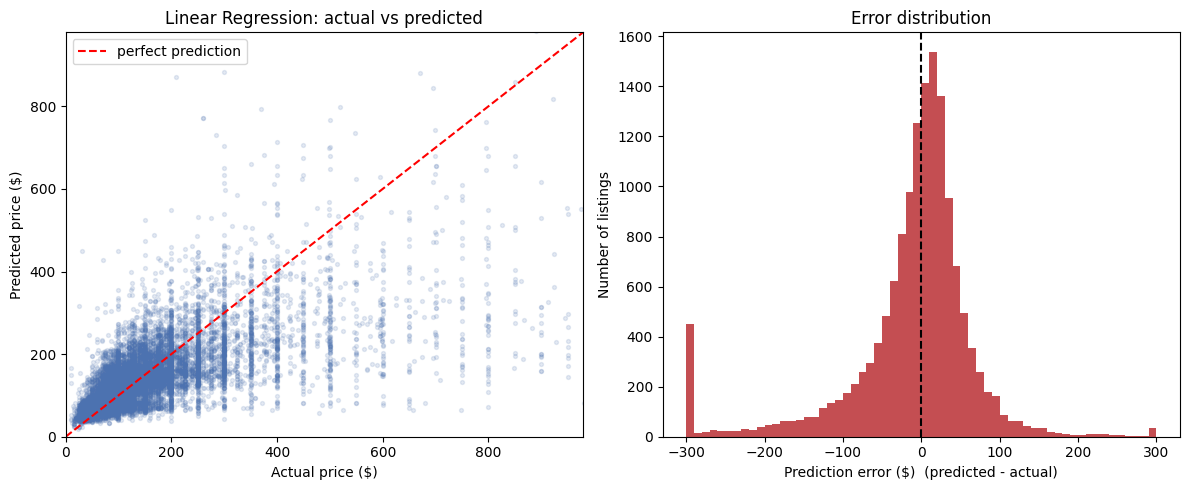

43% of test predictions are within $25 of the real listed price
68% of test predictions are within $50 of the real listed price


In [13]:
lr_model = models["Linear Regression"]
actual = np.exp(y_test)
predicted = np.exp(lr_model.predict(X_test))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: actual vs predicted (zoomed to the 99th percentile for readability)
limit = float(actual.quantile(0.99))
axes[0].scatter(actual, predicted, alpha=0.15, s=8, color="#4C72B0")
axes[0].plot([0, limit], [0, limit], "r--", label="perfect prediction")
axes[0].set_xlim(0, limit); axes[0].set_ylim(0, limit)
axes[0].set_xlabel("Actual price ($)"); axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Linear Regression: actual vs predicted"); axes[0].legend()

# Right: how big are the errors? (errors beyond +-$300 are grouped into the two end bars)
errors = (predicted - actual)
axes[1].hist(errors.clip(-300, 300), bins=60, color="#C44E52")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_xlabel("Prediction error ($)  (predicted - actual)")
axes[1].set_ylabel("Number of listings"); axes[1].set_title("Error distribution")
plt.tight_layout(); plt.show()

within_25 = (np.abs(errors) <= 25).mean() * 100
within_50 = (np.abs(errors) <= 50).mean() * 100
print(f"{within_25:.0f}% of test predictions are within $25 of the real listed price")
print(f"{within_50:.0f}% of test predictions are within $50 of the real listed price")

## 13. Explain the Linear Regression (what drives the price?)

This is the big advantage of Linear Regression: we can read its weights (coefficients).

Because the model predicts **log(price)**, a coefficient `w` means:
*when this feature increases by 1 (or a category is present), the price changes by about* `(e^w − 1) × 100 %`,
*keeping everything else the same.*

A. Effect of +1 unit on the nightly price (all else equal):


,price change (%)
beds,-4.5
accommodates,8.2
bathrooms,16.5
bedrooms,16.9


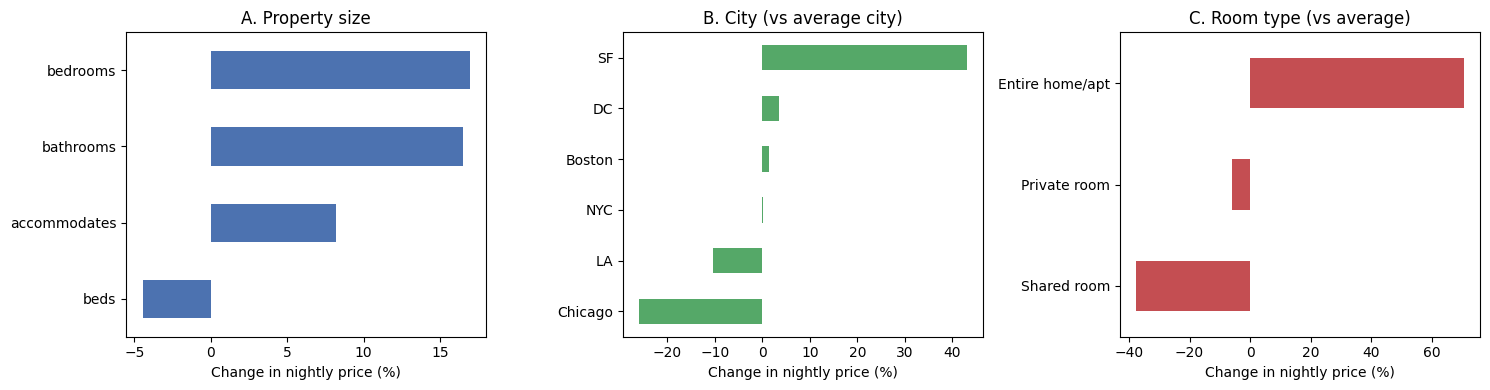


C. Amenities (association, all else equal):


,price change (%)
has_wireless_internet,-10.6
has_parking,-3.3
has_kitchen,-3.1
has_heating,1.1
has_air_conditioning,6.0
has_tv,16.1


These are associations in historical data, not proof of cause and effect.


In [14]:
preprocessing = lr_model.named_steps["preprocessor"]
regressor = lr_model.named_steps["regressor"]

feature_names = preprocessing.get_feature_names_out()
coefficients = pd.Series(regressor.coef_, index=feature_names)
coefficients.index = (coefficients.index
                      .str.replace("categorical__", "", regex=False)
                      .str.replace("numeric__", "", regex=False))

def percent_effect(weights):
    return (np.exp(weights) - 1) * 100

size_features = ["accommodates", "bedrooms", "bathrooms", "beds"]
size_effect = percent_effect(coefficients[size_features]).sort_values()
print("A. Effect of +1 unit on the nightly price (all else equal):")
display(size_effect.round(1).to_frame("price change (%)"))

def category_effect(prefix):
    weights = coefficients[coefficients.index.str.startswith(prefix + "_")]
    weights = weights - weights.mean()
    weights.index = weights.index.str.replace(prefix + "_", "", regex=False)
    return percent_effect(weights).sort_values()

city_effect = category_effect("city")
room_effect = category_effect("room_type")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
size_effect.plot(kind="barh", ax=axes[0], color="#4C72B0", title="A. Property size")
city_effect.plot(kind="barh", ax=axes[1], color="#55A868", title="B. City (vs average city)")
room_effect.plot(kind="barh", ax=axes[2], color="#C44E52", title="C. Room type (vs average)")
for ax in axes:
    ax.set_xlabel("Change in nightly price (%)")
plt.tight_layout(); plt.show()

amenity_effect = percent_effect(coefficients[list(AMENITY_FEATURES)]).sort_values()
print("\nC. Amenities (association, all else equal):")
display(amenity_effect.round(1).to_frame("price change (%)"))
print("These are associations in historical data, not proof of cause and effect.")


## 14. Predict the price of a new listing

`predict_price()` is the function a website will call after the user submits a form.
It checks the inputs, builds a one-row table in the same format as the training data,
and returns the estimated nightly price in dollars.

We use **Linear Regression** as the final model because it only needs simple form inputs
(city, neighbourhood, room type, guests, ...) and it is explainable.

In [15]:
from src.predict_price import predict_price as predict_listing_price

final_model = models["Linear Regression"]
final_model_name = "Linear Regression"
sample_index = X.dropna(subset=list(NUMERIC_FEATURES)).index[0]
sample = X.loc[sample_index]
estimate = predict_listing_price(sample.to_dict(), model=final_model)

print("Prediction example using one complete real listing row")
print(f"  {sample['city']} / {sample['room_type']} / {sample['property_type']}")
print(f"  Actual listed price : ${df_clean.loc[sample_index, 'price']:,.2f}")
print(f"  Model estimate      : ${estimate:,.2f} per night")


Prediction example using one complete real listing row
  NYC / Entire home/apt / Apartment
  Actual listed price : $150.00
  Model estimate      : $137.30 per night


## 15. Try it yourself — type your own listing (optional)

Set `RUN_INTERACTIVE = True` and run this cell to enter your own details.
Press **Enter** without typing to accept the default shown in brackets.
This is exactly what the website form will do later.

In [16]:
RUN_INTERACTIVE = False

def interactive_prediction():
    city = input("City [NYC]: ").strip() or "NYC"
    room_type = input("Room type [Entire home/apt]: ").strip() or "Entire home/apt"
    property_type = input("Property type [Apartment]: ").strip() or "Apartment"
    listing = {
        "city": city,
        "room_type": room_type,
        "property_type": property_type,
        "accommodates": int(input("Accommodates [2]: ") or 2),
        "bathrooms": float(input("Bathrooms [1]: ") or 1),
        "bedrooms": int(input("Bedrooms [1]: ") or 1),
        "beds": int(input("Beds [1]: ") or 1),
        "cleaning_fee": int(input("Cleaning fee? 0/1 [0]: ") or 0),
        "instant_bookable": int(input("Instant bookable? 0/1 [0]: ") or 0),
    }
    for feature in AMENITY_FEATURES:
        listing[feature] = int(input(f"{feature}? 0/1 [0]: ") or 0)
    price = predict_listing_price(listing, model=final_model)
    print(f"\nEstimated price: ${price:,.2f} per night")
    print("Estimate based on historical listing data; not a live market quote.")

if RUN_INTERACTIVE:
    interactive_prediction()
else:
    print("Interactive demo is off. Set RUN_INTERACTIVE = True to enter a listing.")


Interactive demo is off. Set RUN_INTERACTIVE = True to enter a listing.


## 16. Save the trained model (for your website)

We save the model **and** the dropdown options a website form needs (cities, neighbourhoods per city,
room types, ...) in one file with `joblib`. Keep the file together with the same scikit-learn version
that trained it, and never load `.joblib` files from people you do not trust.

**Website idea (later):** the browser (HTML/CSS/JS) cannot run a scikit-learn model directly.
The usual design is:

`HTML form → JavaScript fetch() → small Python API (Flask or FastAPI) → loads this .joblib file → returns the price → JavaScript shows it`

If you want, I can build that Flask API and the HTML page for you as the next step.

In [17]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "airbnb_price_model.joblib"
joblib.dump(final_model, MODEL_PATH)
print(f"Model pipeline saved to: {MODEL_PATH}")

loaded_model = joblib.load(MODEL_PATH)
check_row = X_test.dropna(subset=list(NUMERIC_FEATURES)).iloc[[0]]
loaded_prediction = predict_listing_price(check_row.iloc[0].to_dict(), model=loaded_model)
in_memory_prediction = predict_listing_price(check_row.iloc[0].to_dict(), model=final_model)
same = np.isclose(loaded_prediction, in_memory_prediction, rtol=1e-12, atol=1e-12)
print("Reload check passed:", bool(same))


Model pipeline saved to: models/airbnb_price_model.joblib
Reload check passed: True


## 17. Conclusion

We built a complete **supervised regression** workflow: loading and cleaning the data, turning amenities text
into features, EDA and business insights, train/test split, three models, evaluation in dollars,
model explanation, a price-prediction function and a saved model that a website can use.

### Key points for your report / viva
* **Problem type:** supervised **regression** (the target `price` is a number, not a class).
* **Why log price?** Prices are right-skewed; predicting `log(price)` makes the pattern more linear and stable.
  We convert back with `np.exp()` to report dollars.
* **Why a pipeline?** Imputing and encoding are learned from the training data only, so the test set stays unseen
  (no data leakage), and a new website input goes through exactly the same steps.
* **One-hot encoding** turns categories such as city or room type into 0/1 columns.
* **Baseline vs models:** the median baseline shows how much the model really adds.
* **Linear Regression is explainable:** coefficients show how each feature changes the price in %.
* **Gradient Boosting** is shown only for comparison; it is a bit better but needs exact latitude/longitude and is harder to explain.
* **Metrics:** MAE and RMSE are in dollars; R² is *not* an accuracy percentage.
* **Limitations:** historical *listed* prices (not bookings, occupancy, costs or profit); no photos, text quality, season or
  events; some neighbourhoods have few listings; the model is a reference estimate, not a guarantee.
* **Future work:** add season/date, use text and photos, tune the models, deploy as a web app with a Flask/FastAPI backend.